# Lab 03: Perception

## Opakování: homogenní souřadnice

Bod v rovině $(x, y)$ zapíšeme v homogenních souřadnicích jako vektor o jednu složku delší:

$$
(x, y) \;\mapsto\; \begin{bmatrix} x \\ y \\ 1 \end{bmatrix}.
$$

Všechny násobky $\lambda\,[x, y, 1]^\top$, $\lambda \neq 0$, reprezentují **stejný bod** - například směr paprsku v kamerových souřadnicích. Zpět do kartézských souřadnic se dostaneme vydělením poslední složkou:

$$
\begin{bmatrix} \tilde x \\ \tilde y \\ w \end{bmatrix} \;\mapsto\; \left(\frac{\tilde x}{w}, \frac{\tilde y}{w}\right), \qquad w \neq 0.
$$

Vektory s $w = 0$ neodpovídají žádnému bodu v rovině, ale směru (bodu v nekonečnu).

Proč je to užitečné (viz první cvičení na transformace):

- **Posunutí se stane lineární operací.** Transformaci $\mathrm{SE}(2)$ (rotace $R$ a posunutí $t$) zapíšeme jako jedinou matici $3 \times 3$ a skládání transformací je pak obyčejné násobení matic. Pro bod $p = [x, y]^\top$:
$$
\begin{bmatrix} R & t \\ 0 & 1 \end{bmatrix}
\begin{bmatrix} p \\ 1 \end{bmatrix}
=
\begin{bmatrix} R p + t \\ 1 \end{bmatrix}.
$$
- Ve 3D je to totéž o dimenzi výš: bod $(X, Y, Z) \mapsto [X, Y, Z, 1]^\top$ a $\mathrm{SE}(3)$ je matice $4 \times 4$.
- Díky dělení poslední složkou umí homogenní souřadnice popsat i **nelineární** zobrazení, např. perspektivní projekci kamery, maticovým násobením. 

## Projekce bodu do obrazu: kalibrační matice $K$

Uvažujme model dírkové kamery (pinhole). Bod $P = (X, Y, Z)$ je vyjádřený v souřadném systému kamery: osa $z$ míří ve směru optické osy (dopředu), osa $x$ doprava a osa $y$ dolů.

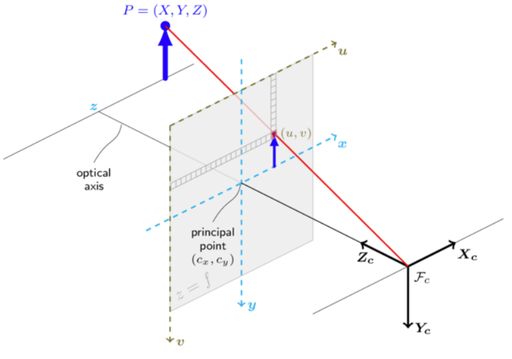

Paprsek z bodu $P$ prochází středem projekce a protíná obrazovou rovinu. V homogenních souřadnicích zapíšeme projekci do pixelu $(u, v)$ jedním násobením **kalibrační maticí** $K$:

$$
\lambda \begin{bmatrix} u \\ v \\ 1 \end{bmatrix}
=
\underbrace{\begin{bmatrix} f_x & 0 & c_x \\ 0 & f_y & c_y \\ 0 & 0 & 1 \end{bmatrix}}_{K}
\begin{bmatrix} X \\ Y \\ Z \end{bmatrix},
$$

kde

- $f_x, f_y$ je ohnisková vzdálenost vyjádřená v pixelech (ve směru $x$ a $y$). Ohnisková vzdálenost souvisí se zorným polem kamery (Field of View, FoV): čím větší ohnisková vzdálenost, tím užší FoV (teleobjektiv, „zoom“), a naopak,
- $(c_x, c_y)$ je hlavní bod (principal point), tj. pixel, kterým prochází optická osa; typicky leží zhruba uprostřed obrázku.

Výsledek násobení $K\,[X, Y, Z]^\top$ ještě **není v pixelech**, je to jen homogenní vektor. Pixelové souřadnice z něj dostaneme až vydělením poslední složkou (tedy $\lambda = Z$):

$$
K \begin{bmatrix} X \\ Y \\ Z \end{bmatrix}
=
\begin{bmatrix} f_x X + c_x Z \\ f_y Y + c_y Z \\ Z \end{bmatrix}
\quad\Longrightarrow\quad
u = f_x \frac{X}{Z} + c_x, \qquad v = f_y \frac{Y}{Z} + c_y.
$$

Klíčové pozorování: **samotný 3D bod $[X, Y, Z]^\top$ můžeme chápat jako homogenní souřadnice bodu v obraze**. Perspektivní dělení hloubkou $Z$, které dělá projekci nelineární (v euklidovském prostoru), je přesně ten krok „vyděl poslední složkou“ z předchozí sekce. Matice $K$ sama je lineární a jen škáluje a posouvá výsledek do pixelů.

Důsledky:

- Všechny body na jednom paprsku, $\mu\,[X, Y, Z]^\top$ pro $\mu > 0$, se promítnou do **stejného pixelu**. Hloubka se projekcí ztrácí.
- Opačným směrem z pixelu dostaneme jen směr paprsku, nikoli bod:
$$
K^{-1} \begin{bmatrix} u \\ v \\ 1 \end{bmatrix} = \begin{bmatrix} X/Z \\ Y/Z \\ 1 \end{bmatrix}.
$$
- Pokud je bod zadaný ve světových souřadnicích, nejdřív ho transformací $T_{CW} \in \mathrm{SE}(3)$ převedeme do souřadnic kamery:
$$
\lambda \begin{bmatrix} u \\ v \\ 1 \end{bmatrix} = K \, T_{CW} \begin{bmatrix} X_w \\ Y_w \\ Z_w \\ 1 \end{bmatrix}.
$$

## Homografie

Často potřebujeme převádět souřadnice bodů **mezi dvěma rovinami**. Typický příklad je vyfocený papír ležící na stole: bod na papíře má souřadnice $(x, y)$ v milimetrech, v obrázku má souřadnice $(u, v)$ v pixelech, a chceme umět přecházet z jedněch do druhých. Kamera se na papír může dívat šikmo, takže obdélník papíru se v obrázku zobrazí jako obecný čtyřúhelník. Takový vztah nepopíše ani rotace s posunutím, ani afinní transformace, ale právě homografie.

**Důležité:** souřadnice na papíře uvažujeme **pouze v rovině papíru**, tj. jsou to 2D souřadnice $(x, y)$, nikoli 3D bod v prostoru. Nejde tedy o projekci $3\text{D} \to 2\text{D}$ jako u kalibrační matice $K$, ale o zobrazení $2\text{D} \to 2\text{D}$ mezi dvěma rovinami. Na rozdíl od projekce se při něm neztrácí žádná informace: homografie je invertibilní a z pixelu umíme jednoznačně dopočítat bod na papíře.

**Homografii** (projektivní transformace roviny) vyjádříme jako matici $H$ o rozměru $3 \times 3$. Pokud jí vynásobíme 2D bod (v homogenních souřadnicích) z jedné roviny, dostane odpovídající bod v druhé rovině:

$$
\lambda \begin{bmatrix} u' \\ v' \\ 1 \end{bmatrix}
=
\underbrace{\begin{bmatrix} h_{11} & h_{12} & h_{13} \\ h_{21} & h_{22} & h_{23} \\ h_{31} & h_{32} & h_{33} \end{bmatrix}}_{H}
\begin{bmatrix} u \\ v \\ 1 \end{bmatrix}.
$$

Stejně jako u projekce kamerou je výsledek násobení jen homogenní vektor a kartézské souřadnice $(u', v')$ dostaneme vydělením poslední složkou.

Vlastnosti:

- přímky se zobrazí na přímky,
- rovnoběžnost se obecně **nezachovává** (koleje vyfocené šikmo se v obrázku sbíhají),
- nezachovávají se ani vzdálenosti, úhly a poměry délek.

### Kolik má homografie stupňů volnosti (DoF)?

Matice $H$ má 9 prvků, ale $H$ a $\mu H$ pro libovolné $\mu \neq 0$ popisují **stejnou** homografii, protože násobek se ztratí při dělení poslední složkou. Jeden stupeň volnosti tedy padne na měřítko a homografie má pouze 8 stupňů volnosti (DoF). 

Jedna dvojice odpovídajících si bodů $(u, v) \leftrightarrow (u', v')$ dává 2 rovnice (pro každou souřadnici jednu). K určení homografie proto potřebujeme **alespoň 4 korespondence**, z nichž žádné 3 neleží na jedné přímce. Pokud jich máme víc (a jsou zatížené šumem), řešíme přeurčenou soustavu například metodou nejmenších čtverců.

### Kde se homografie v praxi objeví

- **Rovina ve scéně a její obraz.** Vztah mezi souřadnicemi na rovinném objektu (papír, stůl, podlaha) a pixely v obrázku je homografie, a to pro libovolnou polohu kamery. Stačí znát 4 body na papíře a jejich pixely, a pak umíme převádět souřadnice oběma směry, např. zjistit, kde na stole leží detekovaný objekt, nebo „narovnat“ šikmo vyfocený dokument.
- **Panorama.** Pokud kamera mezi snímky pouze rotuje a střed projekce se nehýbe, jsou snímky svázané homografií bez ohledu na hloubku scény. Díky tomu je jde složit do jednoho panoramatu.

## Praktická ukázka: odhad homografie z obrázku

Na fotce níže leží na stole papír A4. Odhadneme homografii mezi rovinou papíru (souřadnice v milimetrech) a obrázkem (souřadnice v pixelech) a pomocí ní obrázek „narovnáme“ do pohledu shora.

Obrázek načteme pomocí `cv2.imread`. OpenCV ukládá barvy v pořadí **BGR**, zatímco matplotlib očekává **RGB**, proto před vykreslením převedeme pořadí kanálů pomocí `cv2.cvtColor`. Obrázek je NumPy pole o tvaru `(výška, šířka, 3)`.

In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

img = cv2.imread("aruco.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print(img.shape)

plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.show()

Korespondence bodů tentokrát zadáme ručně: jako body použijeme 4 rohy papíru. Jejich polohu v obrázku jsme odečetli z fotky, jejich polohu na papíře známe z rozměrů A4. Papír leží na šířku, tedy 297 mm ve směru osy $x$ a 210 mm ve směru osy $y$. Počátek souřadnic na papíře volíme v levém horním rohu.

Pozor na pořadí: $i$-tý bod na papíře musí odpovídat $i$-tému bodu v obrázku.

Homografii $H$, která převádí souřadnice na papíře na pixely, odhadneme funkcí `cv2.findHomography`. Pro 4 body je řešení přesné, pro více bodů by funkce řešila úlohu nejmenších čtverců. (Kromě matice vrací i masku inlierů, kterou nyní nepotřebujeme.)

Pro kontrolu promítneme rohy papíru pomocí $H$ do obrázku: přidáme jedničku (homogenní souřadnice), vynásobíme maticí a vydělíme poslední složkou. Měli bychom dostat zpět `img_pts`.

In [ ]:
# rohy papíru v pixelech (u, v): levý horní, pravý horní, pravý dolní, levý dolní
img_pts = np.array([[334, 114], [843, 278], [676, 686], [56, 357]], dtype=np.float32)

# tytéž rohy v souřadnicích papíru (x, y) v milimetrech
paper_pts = np.array([[0, 0], [297, 0], [297, 210], [0, 210]], dtype=np.float32)

plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.plot(*img_pts.T, "o", color="red")
for (u, v), (x, y) in zip(img_pts, paper_pts):
    plt.annotate(f"({x:.0f}, {y:.0f}) mm", (u, v), color="red", backgroundcolor=(1, 1, 1, 0.7), xytext=(5, -5), textcoords="offset points")
plt.show()

In [ ]:
H, _ = cv2.findHomography(paper_pts, img_pts)

print("Homografie H:")
with np.printoptions(suppress=True, precision=4):
    print(H.round(4))
print()

paper_pts_h = np.hstack([paper_pts, np.ones((4, 1))])  # (4, 2) -> (4, 3) homogenní souřadnice
# alternativně například: np.pad(paper_pts, ((0,0), (0,1)), constant_values=1)
projected = (H @ paper_pts_h.T) # paper_pts_h obsahuje body po řádcích, takže je třeba transponovat
projected = projected[:2] / projected[2]
projected = projected.T  # (2, 4) -> (4, 2)

print("Body v obrázku:")
print(img_pts)
print()
print("Body z papíru po transformaci homografií:")
print(projected)

Obrázek teď „narovnáme“. Chceme převést pixely obrázku na souřadnice na papíře, tedy použít **inverzní** homografii $H^{-1}$. Funkce `cv2.warpPerspective` dostane obrázek, matici transformace (ze vstupního obrázku do výstupního) a velikost výstupu jako `(šířka, výška)`.

In [ ]:
rectified = cv2.warpPerspective(img, np.linalg.inv(H), (297, 210))

plt.figure(figsize=(8, 6))
plt.imshow(rectified)
plt.show()

## Detekce ArUco markerů

V předchozí ukázce jsme body pro odhad homografie (rohy papíru) zadali ručně odečtením z obrázku. Místo toho bychom chtěli body v obrázku najít **automaticky**, a to tak, abychom zároveň věděli, kterému bodu ve scéně odpovídají. Přesně k tomu slouží speciální značky, jako např. ArUco markery.

ArUco marker je čtverec s černým okrajem, uvnitř kterého je mřížka černých a bílých políček. Políčka kódují binární číslo, které určuje **ID markeru**. Markery jsou navržené tak, aby se daly v obrázku rychle a spolehlivě najít a aby z nich šlo určit nejen polohu, ale i **natočení**.

Detekce probíhá zhruba takto:

1. obrázek se převede na šedotónový a prahuje se (černý okraj vs. bílé okolí),
2. najdou se obrysy, které lze aproximovat čtyřúhelníkem, tj. kandidáti na marker,
3. každý kandidát se pomocí **homografie** „narovná“ na čtverec (přesně jako papír v předchozí sekci) a přečtou se jednotlivé bity mřížky,
4. přečtený kód se porovná se všemi markery ve **slovníku**, a to ve všech 4 otočeních o 90°. Pokud se shoduje, kandidát je přijat.

**Proč markery nesmějí být symetrické.** Detektor neví, jak je marker v obrázku natočený, a proto zkouší všechna 4 otočení. Kdyby byl kód symetrický vůči otočení (např. o 180°), shodoval by se ve více natočeních a nešlo by rozhodnout, který roh je který. Kódy ve slovníku jsou proto vybrané tak, aby žádný nebyl rotačně symetrický a aby se lišily od ostatních kódů i od svých vlastních otočení v co nejvíce bitech.

Díky tomu má každý marker **pevně daný levý horní roh** (ten, který je vlevo nahoře ve vygenerovaném obrázku markeru) a detektor vrací rohy vždy ve stejném pořadí - od levého horního dokola podle směru hodinových ručiček: levý horní, pravý horní, pravý dolní, levý dolní. Každý roh má tedy svou identitu nezávisle na tom, jak je marker natočený. To je přesně to, co potřebujeme pro korespondence bodů, např. pro odhad homografie nebo polohy kamery.

### Slovník markerů

Slovník (dictionary) je pevná množina kódů, které detektor hledá. Tady používáme `DICT_4X4_50`:

- `4X4` znamená, že vnitřní mřížka má $4 \times 4$ bitů (+ vnější černý okraj),
- `50` znamená, že slovník obsahuje 50 markerů s ID 0 až 49.

Volba slovníku je kompromis. Větší mřížka (např. `6X6`) umožňuje více markerů a větší odolnost vůči chybám, ale marker musí být v obrázku větší, aby šly bity přečíst. Menší počet markerů ve slovníku znamená, že se kódy mohou navzájem více lišit, a detekce je tak spolehlivější (méně falešných detekcí). Markery je nutné detekovat se **stejným slovníkem**, se kterým byly vygenerovány (viz `99_generate_aruco_markers.py`).

Pro představu vykreslíme první čtyři markery ze slovníku.

In [ ]:
aruco_dict = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_4X4_50)

fig, axes = plt.subplots(1, 4, figsize=(10, 3))
for marker_id, ax in enumerate(axes):
    ax.imshow(aruco_dict.generateImageMarker(marker_id, sidePixels=120), cmap="gray")
    ax.set_title(f"ID {marker_id}")
    ax.axis("off")
plt.show()

### Detekce v obrázku

Detektor vytvoříme ze slovníku pomocí `cv2.aruco.ArucoDetector` a markery najdeme metodou `detectMarkers` na šedotónovém obrázku. Pro obrázek s `N` detekovanými markery vrací:

- `corners`: pole velikosti `N`, pro každý marker pole tvaru `(1, 4, 2)` s pixelovými souřadnicemi jeho 4 rohů v pořadí levý horní, pravý horní, pravý dolní, levý dolní,
- `ids`: pole velikossti `(N,)` s ID nalezených markerů,
- `rejected`: kandidáty, kteří vypadali jako marker, ale jejich kód neodpovídal žádnému markeru ve slovníku.

In [ ]:
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
detector = cv2.aruco.ArucoDetector(aruco_dict)
corners, ids, rejected = detector.detectMarkers(gray)

print("ID markerů:", ids)
print("\nRohy prvního markeru:")
print(corners[0])

Výsledek zobrazíme. Funkce `cv2.aruco.drawDetectedMarkers` vykreslí obrysy markerů a jejich ID přímo do obrázku (proto pracujeme s kopií), a navíc vyznačí levý horní roh každého markeru.

In [ ]:
img_markers = img.copy()
cv2.aruco.drawDetectedMarkers(img_markers, corners, ids)

plt.figure(figsize=(8, 6))
plt.imshow(img_markers)
plt.show()

Pro představu, jak detektor „vidí“ jednotlivé kandidáty, je můžeme sami vyříznout a narovnat (krok 3 výše). Pro každý čtyřúhelník spočítáme homografii z jeho 4 rohů na čtverec pomocí `cv2.getPerspectiveTransform` (to je `cv2.findHomography` pro právě 4 body) a obrázek pomocí ní transformujeme (`cv2.warpPerspective`). Do výřezu dokreslíme mřížku $6 \times 6$ políček (4 × 4 bity + okraj), ze které detektor čte bity.

Nejdřív vykreslíme do obrázku zamítnuté kandidáty:

In [ ]:
img_rejected = img.copy()
cv2.aruco.drawDetectedMarkers(img_rejected, rejected, borderColor=(255, 0, 0))

print("Počet zamítnutých kandidátů:", len(rejected))
plt.figure(figsize=(8, 6))
plt.imshow(img_rejected)
plt.show()

Teď kandidáty vyřízneme. V horním řádku jsou přijaté markery. Díky pevnému pořadí rohů jsou po narovnání všechny ve stejné orientaci jako ve slovníku výše. Ve spodním řádku je několik zamítnutých kandidátů.

In [ ]:
def crop_candidate(gray, quad, size=120):
    """Narovná čtyřúhelník `quad` (4 rohy v pixelech) na čtverec o straně `size` pixelů."""
    square = np.array([[0, 0], [size, 0], [size, size], [0, size]], dtype=np.float32)
    H_crop = cv2.getPerspectiveTransform(quad.reshape(4, 2).astype(np.float32), square)
    return cv2.warpPerspective(gray, H_crop, (size, size))


def show_crop(ax, crop, title, cells=6):
    ax.imshow(crop, cmap="gray", vmin=0, vmax=255)
    step = crop.shape[0] / cells
    for k in range(1, cells):
        ax.axhline(k * step, color="red", linewidth=1)
        ax.axvline(k * step, color="red", linewidth=1)
    ax.set_title(title)


rejected_crops = [crop_candidate(gray, quad) for quad in rejected]
rejected_crops = sorted(rejected_crops, key=np.std, reverse=True)[:4]

n_cols = max(len(corners), len(rejected_crops))
fig, axes = plt.subplots(2, n_cols, figsize=(2.5 * n_cols, 5.5))
for ax in axes.ravel():
    ax.axis("off")
for ax, quad, marker_id in zip(axes[0], corners, ids):
    show_crop(ax, crop_candidate(gray, quad), f"ID {marker_id}")
for ax, crop in zip(axes[1], rejected_crops):
    show_crop(ax, crop, "zamítnut")
plt.show()

## Odhad homografie z detekovaných markerů

Teď můžeme zopakovat odhad homografie papíru, tentokrát bez ručního zadávání bodů. Na papíře jsou 4 markery o velikosti 30 mm, každý 10 mm od okrajů papíru: ID 0 vlevo nahoře, ID 1 vpravo nahoře, ID 2 vlevo dole a ID 3 vpravo dole. Pro každý marker tedy známe souřadnice jeho 4 rohů na papíře (v milimetrech) a díky ID a pevnému pořadí rohů víme, kterému detekovanému pixelu který odpovídá.

Dostaneme tak 16 korespondencí místo 4. Soustava je přeurčená a `cv2.findHomography` ji řeší metodou nejmenších čtverců, takže šum v detekci jednotlivých rohů se částečně vyruší.

In [ ]:
marker_size_mm = 30
# poloha levého horního rohu každého markeru na papíře (x, y) v mm
marker_offsets = {0: (10, 10), 1: (257, 10), 2: (10, 170), 3: (257, 170)}
# rohy markeru vůči jeho levému hornímu rohu, ve stejném pořadí jako vrací detektor
marker_square = np.array([[0, 0], [1, 0], [1, 1], [0, 1]]) * marker_size_mm

paper_pts_16 = np.concatenate([marker_square + marker_offsets[i] for i in ids]).astype(np.float32)
img_pts_16 = np.concatenate([c.reshape(4, 2) for c in corners])

H_markers, _ = cv2.findHomography(paper_pts_16, img_pts_16)

plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.plot(*img_pts_16.T, "o", color="red", markersize=4)
plt.show()

Pro kontrolu body promíneme zpět homografií a změříme, o kolik pixelů se liší od detekovaných rohů (reprojekční chyba):

In [ ]:
# reprojekční chyba: o kolik pixelů se promítnuté body liší od detekovaných
projected_16 = cv2.perspectiveTransform(paper_pts_16[None], H_markers)[0]
errs = np.linalg.norm(projected_16 - img_pts_16, axis=1)
print("Reprojekční chyby [px]:\n", errs.round(2))
print("Průměrná reprojekční chyba [px]:", errs.mean().round(2))

Chyby jsou kolem jednoho pixelu, tedy homografie dobře sedí na všech 16 bodů. Obrázek opět narovnáme pomocí inverzní homografie.

In [ ]:
rectified_markers = cv2.warpPerspective(img, np.linalg.inv(H_markers), (297, 210))

plt.figure(figsize=(8, 6))
plt.imshow(rectified_markers)
plt.show()

## Odhad polohy markerů: SE(3)

Z detekovaných rohů markeru umíme spočítat nejen homografii, ale i **3D polohu markeru vůči kameře**, tedy transformaci $\mathrm{SE}(3)$ složenou z rotace $R$ a posunutí $t$. Potřebujeme k tomu navíc:

- **kalibraci kamery**, tj. matici $K$ (a koeficienty zkreslení objektivu); jak kameru zkalibrovat pomocí fotek šachovnice, popisuje například tento [OpenCV tutoriál](https://docs.opencv.org/4.10.0/dc/dbb/tutorial_py_calibration.html),
- **fyzickou velikost markeru**, tady 3 cm.

Podobně jako jsme homografii hledali z korespondencí 4 bodů na papíře a v obrázku, tady máme korespondence 4 rohů markeru v jeho vlastním 3D souřadném systému a jejich pixelů v obrázku. Úloze najít polohu kamery z korespondencí $n$ 3D bodů a jejich 2D průmětů se říká **Perspective-n-Point (PnP)**. V OpenCV ji řeší funkce `cv2.solvePnP`, která (podle zvolené metody analyticky nebo optimalizací) najde $R$ a $t$ takové, aby promítnuté 3D body $K (R X + t)$ co nejlépe odpovídaly detekovaným pixelům. Pro čtvercové markery má speciální metodu `cv2.SOLVEPNP_IPPE_SQUARE`.

Nejdřív načteme kalibraci a zadefinujeme 3D souřadnice rohů markeru v jeho souřadném systému: počátek je ve středu markeru, osa $x$ míří doprava, $y$ nahoru a $z$ ven z markeru. Rohy musí být ve **stejném pořadí**, v jakém je vrací detektor (levý horní, pravý horní, pravý dolní, levý dolní). Velikost zadáváme v metrech, takže i výsledné posunutí $t$ bude v metrech.

In [ ]:
calibration = np.load("calibration.npz")
K = calibration["K"]
dist = calibration["dist"]
print("K =\n", K)

marker_size = 0.03  # m
s = marker_size / 2
marker_points = np.array([[-s, s, 0], [s, s, 0], [s, -s, 0], [-s, -s, 0]], dtype=np.float32)

Pro každý marker zavoláme `cv2.solvePnP`. Funkce vrací rotaci jako vektor `rvec` v reprezentaci osa–úhel (směr vektoru je osa rotace, jeho velikost úhel v radiánech), na rotační matici ho převedeme pomocí `cv2.Rodrigues`. Výsledné $R$ a $t$ převádějí souřadnice z rámce markeru do rámce kamery, tj. $t$ je poloha středu markeru v souřadnicích kamery.

In [ ]:
rvecs, tvecs = [], []
for c, marker_id in zip(corners, ids.ravel()):
    _, rvec, tvec = cv2.solvePnP(marker_points, c, K, dist, flags=cv2.SOLVEPNP_IPPE_SQUARE)
    rvecs.append(rvec)
    tvecs.append(tvec)

    R, _ = cv2.Rodrigues(rvec)
    #print(f"ID {marker_id}: t = {tvec.ravel().round(3)} m")
    #print(R.round(3), end="\n\n")

Nakonec vykreslíme souřadné systémy markerů funkcí `cv2.drawFrameAxes`.

In [ ]:
img_axes = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
for rvec, tvec in zip(rvecs, tvecs):
    cv2.drawFrameAxes(img_axes, K, dist, rvec, tvec, 0.04)

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(img_axes, cv2.COLOR_BGR2RGB))
plt.show()

**Poznámka:** Výše jsme odhadli polohu každého markeru zvlášť, ze 4 rohů. Pokud ale víme, že všechny markery leží ve stejné rovině, a známe jejich vzájemné umístění, můžeme 3D souřadnice rohů všech markerů vyjádřit v jednom společném souřadném systému papíru a zavolat `cv2.solvePnP` na všechny body najednou. Dostaneme tak jednu konzistentní transformaci $\mathrm{SE}(3)$ pro celý papír místo čtyř mírně odlišných. Odhad je navíc přesnější, protože vychází z více bodů, které jsou od sebe dál. OpenCV pro takové sestavy markerů nabízí i hotovou podporu přes `cv2.aruco.Board`.

## Domácí úkol: homografie z obrázků obruče

Cílem domácího úkolu je vyzkoušet si práci s OpenCV a spočítat homografii. Robot drží v chapadle obruč a postupně s ní najíždí do 17 různých poloh těsně nad stolem. Pro každou polohu kamera nad stolem pořídila snímek. Na vstupu tedy máme:

- **17 obrázků** `hw_data/hoop_grid_image_{i}.png` pro $i = 0, \dots, 16$,
- soubor **`hw_data/hoop_positions.json`** se seznamem 17 záznamů o poloze obruče v souřadnicích robota. Každý záznam obsahuje natočení `RPY` (roll, pitch, yaw v radiánech) a posunutí `translation_vector` $(x, y, z)$ v metrech.

Obrázek s koncovkou `_i.png` odpovídá záznamu na indexu `i` v JSONu. Ukažme si první obrázek a odpovídající záznam.

In [ ]:
import json
from pathlib import Path

data_dir = Path("hw_data")
hoop_images = [cv2.imread(str(data_dir / f"hoop_grid_image_{i}.png")) for i in range(17)]
with open(data_dir / "hoop_positions.json") as f:
    hoop_positions = json.load(f)

print("Rozměry obrázku:", hoop_images[0].shape)
print("Záznam s indexem 0:", json.dumps(hoop_positions[0], indent=2))

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(hoop_images[0], cv2.COLOR_BGR2RGB))
plt.title("hoop_grid_image_0.png")
plt.show()

Obruč je vždy ve stejné výšce nad stolem, takže složka $z$ posunutí je ve všech záznamech stejná (a stejné je i natočení). Všechny polohy středu obruče tedy leží v jedné rovině rovnoběžné se stolem (viz 3D graf níže) a pro homografii nám stačí jejich složky $x, y$.

In [ ]:
hoop_xyz = np.array([pos["translation_vector"] for pos in hoop_positions])

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(projection="3d")
ax.scatter(*hoop_xyz.T)
for i, (x, y, z) in enumerate(hoop_xyz):
    ax.text(x, y, z, f" {i}")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_zlabel("z [m]")
# stejný rozsah na všech osách a krychlový box -> osy mají stejné měřítko
half_range = np.ptp(hoop_xyz, axis=0).max() / 2 + 0.02
center = hoop_xyz.mean(axis=0)
ax.set_xlim(center[0] - half_range, center[0] + half_range)
ax.set_ylim(center[1] - half_range, center[1] + half_range)
ax.set_zlim(0, 2 * half_range)
ax.set_box_aspect((1, 1, 1))
plt.show()

**Cíl úkolu** je naimplementovat funkci `find_hoop_homography(images, hoop_positions)` v `src/robotics_toolbox/utils/perception.py`, která

1. **detekuje střed obruče** ve všech obrázcích (v pixelech),
2. **spočítá homografii** $H$ z roviny obrazu (pixely) do roviny obruče (souřadnice $x, y$ z JSONu v metrech), tj. pro střed obruče $(u, v)$ v $i$-tém obrázku má platit
$$
\lambda \begin{bmatrix} x_i \\ y_i \\ 1 \end{bmatrix} = H \begin{bmatrix} u_i \\ v_i \\ 1 \end{bmatrix}.
$$

Máme tedy 17 korespondencí bod v obrázku ↔ bod na stole, stejně jako u papíru s markery, jen místo rohů markerů hledáme střed obruče.

## Nápověda: hledání objektu přímo v obraze

Jednou z možností, jak obruč v obrázku najít, je použít klasické metody zpracování obrazu. Ukážeme si několik základních nástrojů z OpenCV.

### Detekce hran

Hrana je místo, kde se prudce mění jas obrázku, tj. kde je velký gradient jasu. Jeden z nejpoužívanějších je **Cannyho detektor hran** ([`cv2.Canny`](https://docs.opencv.org/4.10.0/dd/d1a/group__imgproc__feature.html#ga04723e007ed888ddf11d9ba04e2232de), viz také [tutoriál](https://docs.opencv.org/4.10.0/da/d22/tutorial_py_canny.html)). Pracuje na šedotónovém obrázku a vrací binární obrázek hran (0 a 255). Má dva prahy:

- pixely s gradientem nad **horním prahem** jsou jistě hrany,
- pixely s gradientem pod **dolním prahem** hranami nejsou,
- pixely mezi prahy jsou hranou jen tehdy, když navazují na jistou hranu.

Menší prahy najdou více hran (i slabých a šumu), větší prahy ponechají jen výrazné hrany. Šum v obrázku vytváří falešné hrany, proto se obrázek před detekcí obvykle mírně rozmaže (např. `cv2.GaussianBlur`).

In [ ]:
hoop_img = hoop_images[0]
gray = cv2.cvtColor(hoop_img, cv2.COLOR_BGR2GRAY)
gray = cv2.GaussianBlur(gray, (5, 5), 0)  # rozmazání potlačí šum

edges_low = cv2.Canny(gray, threshold1=20, threshold2=50)
edges_high = cv2.Canny(gray, threshold1=100, threshold2=200)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Šedotónový obrázek")
axes[1].imshow(edges_low, cmap="gray")
axes[1].set_title("Canny, prahy 20 / 50")
axes[2].imshow(edges_high, cmap="gray")
axes[2].set_title("Canny, prahy 100 / 200")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Hledání podle barvy

Obruč má výrazný modrý okraj, takže ji můžeme hledat **podle barvy**. Pro každý pixel spočítáme, jak daleko je jeho barva od referenční barvy $c$, např. jako euklidovskou vzdálenost v barevném prostoru BGR:

$$
d(u, v) = \left\| I(u, v) - c \right\|_2.
$$

Díky broadcastingu v NumPy to jde spočítat pro celý obrázek najednou, bez cyklů. Referenční barvu tady pro ukázku vezmeme z jednoho pixelu na okraji obruče. Pozor, obrázky z `cv2.imread` jsou v BGR a hodnoty jsou `uint8`, proto je před odečítáním převedeme na `float` (jinak by odečítání přetékalo).

In [ ]:
hoop_img = hoop_images[0]
ref_color = np.array([255,50,50])
print("Referenční barva (BGR):", ref_color)

color_dist = np.linalg.norm(hoop_img.astype(float) - ref_color, axis=2)  # (H, W, 3) -> (H, W)

plt.figure(figsize=(10, 6))
plt.imshow(color_dist, cmap="gray")
plt.colorbar(label="vzdálenost od referenční barvy")
plt.show()

**Prahování.** Pixely, jejichž barva je dostatečně blízko referenční barvě, označíme jako popředí. Dostaneme binární masku. OpenCV pro další zpracování očekává masku typu `uint8` s hodnotami 0 a 255. Práh je potřeba zvolit experimentálně: příliš malý práh obruč „rozbije“ na kousky, příliš velký přidá do masky i okolí.

In [ ]:
threshold = 175
mask = (color_dist < threshold).astype(np.uint8) * 255

plt.figure(figsize=(10, 6))
plt.imshow(mask, cmap="gray")
plt.show()

V masce je kromě obruče i část chapadla, robota a jeho kabelu. Potřebujeme tedy rozlišit jednotlivé souvislé oblasti a vybrat tu správnou.

**Kontury.** Funkce `cv2.findContours` najde hranice souvislých oblastí v binární masce. Vrací seznam kontur, každá je pole bodů tvaru `(N, 1, 2)`. Parametr `cv2.RETR_EXTERNAL` říká, že chceme jen vnější hranice (bez děr uvnitř oblastí), `cv2.CHAIN_APPROX_SIMPLE` zjednoduší rovné úseky kontury na jejich koncové body. Kontury vykreslíme funkcí `cv2.drawContours`.

In [ ]:
contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print("Počet kontur:", len(contours))

img_contours = cv2.cvtColor(hoop_img, cv2.COLOR_BGR2RGB)
cv2.drawContours(img_contours, contours, -1, color=(255, 0, 0), thickness=2)  # -1 = všechny kontury

plt.figure(figsize=(10, 6))
plt.imshow(img_contours)
plt.show()

Většina kontur jsou malé kousky šumu. Abychom vybrali tu, která odpovídá obruči, můžeme pro každou konturu spočítat různé vlastnosti, například

- **obsah** $S$: [`cv2.contourArea`](https://docs.opencv.org/4.10.0/d3/dc0/group__imgproc__shape.html#ga2c759ed9f497d4a618048a2f56dc97f1),
- **obvod** $o$: [`cv2.arcLength`](https://docs.opencv.org/4.10.0/d3/dc0/group__imgproc__shape.html#ga8d26483c636be6b35c3ec6335798a47c),
- **kruhovitost** (circularity), tedy jak moc se kontura podobá kruhu:
$$
C = \frac{4 \pi S}{o^2}.
$$
Pro kruh je $S = \pi r^2$ a $o = 2 \pi r$, takže $C = 1$. Pro všechny ostatní tvary je $C < 1$ a čím je tvar protáhlejší nebo členitější, tím je $C$ menší.

Další vlastnosti kontur (těžiště, opsaná kružnice, konvexní obal, …) popisuje [OpenCV tutoriál o vlastnostech kontur](https://docs.opencv.org/4.10.0/dd/d49/tutorial_py_contour_features.html).

## Nápověda: Houghova transformace

Druhou možností je **Houghova transformace**. Ta hledá v obrázku tvary, které lze popsat několika parametry (přímky, kružnice, …). Myšlenka je jednoduchá: každý bod hrany v obrázku **hlasuje** pro všechny tvary, které jím mohou procházet. Hlasy se sčítají v tzv. **akumulátoru**, tj. v diskretizovaném prostoru parametrů. Tvary, které v obrázku opravdu jsou, dostanou hlas od mnoha bodů a v akumulátoru vytvoří výrazné maximum.

### Přímky

Klasicky popisujeme přímku obecnou rovnicí

$$
a x + b y + c = 0.
$$

Pro akumulátor se ale tato parametrizace nehodí ze dvou důvodů:

- **není jednoznačná**: $(a, b, c)$ a $\mu (a, b, c)$ pro libovolné $\mu \neq 0$ popisují stejnou přímku, takže jedna přímka by měla v akumulátoru nekonečně mnoho buněk a hlasy by se rozptýlily,
- **parametry jsou neomezené**: $a, b, c$ mohou nabývat libovolných hodnot, takže prostor parametrů nejde pokrýt konečným akumulátorem.
- **směrnicový tvar nepomůže**: nejednoznačnosti bychom se mohli zbavit vydělením $b$, čímž dostaneme směrnicový tvar $y = kx + q$. V něm ale **nejde reprezentovat svislé přímky** ($b = 0$, tedy $k \to \infty$) a pro téměř svislé přímky je $k$ libovolně velké, takže problém s neomezenými parametry zůstává.

Místo ní se proto používá **normálový tvar**

$$
r = x \cos \theta + y \sin \theta,
$$

kde $r$ je vzdálenost přímky od počátku a $\theta$ úhel kolmice (normály) spuštěné z počátku na přímku:

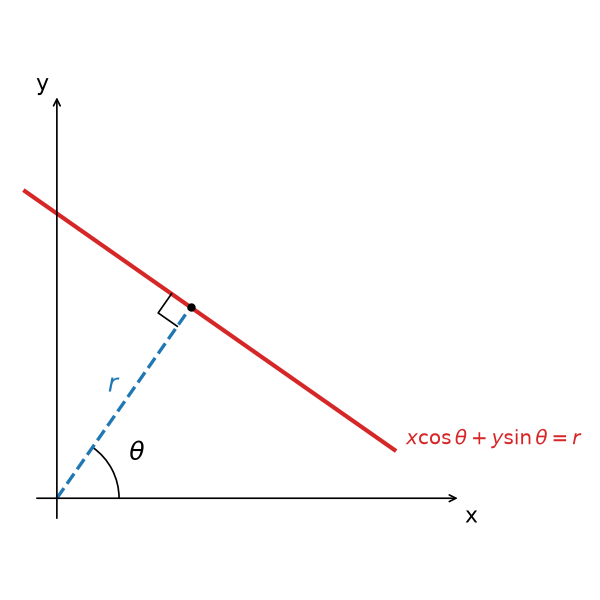

Každá přímka má jediné $(\theta, r)$ a oba parametry jsou omezené: stačí $\theta \in [0, \pi)$ (připustíme-li záporné $r$) a $|r|$ je nejvýše délka úhlopříčky obrázku. Bod $(x, y)$ v obrázku leží na nekonečně mnoha přímkách. V prostoru parametrů $(\theta, r)$ jim odpovídá **sinusoida** $r(\theta) = x \cos\theta + y \sin\theta$. Body, které leží na jedné přímce, mají sinusoidy, které se **protínají v jednom bodě** $(\theta^*, r^*)$, a to jsou právě parametry hledané přímky.

Ukážeme si to na syntetickém příkladu:
 1. V obrázku jsme detekovali hrany, včetně hrany přímky kterou chceme nalézt. Z nich si pro příklad vykreslíme několik bodů na přímce a několik náhodných bodů mimo přímku (šum).
 2. Pro každý detekovaný bod $(x,y)$ pak uvažujeme všechny přímky které jím prochází, tedy zvolíme si $\theta$.
 3. Pro každou takovou přímku dopočítáme $r$ dosazením do normálového tvaru, a tím získáme souřadnice $(\theta, r)$ v akumulátoru.
 4. Hodnotu akumulátor v bodě $(\theta, r)$ inkrementujeme.

In [ ]:
from matplotlib.patches import ConnectionPatch

rng = np.random.default_rng(0)
x_line = np.linspace(10, 90, 8)
pts = np.vstack([
    np.column_stack([x_line, 0.5 * x_line + 20]),  # body na přímce
    rng.uniform(0, 100, size=(8, 2)),              # šum
])

# diskretizace akumulátoru: úhel po 2°, vzdálenost po 5 px
thetas = np.deg2rad(np.arange(0, 180, 2))
r_step = 5
r_max = int(np.ceil(np.hypot(100, 100) / r_step))

# každý bod hlasuje pro všechna (theta, r), tj. pro všechny přímky, které jím procházejí
rs = pts[:, 0:1] * np.cos(thetas) + pts[:, 1:2] * np.sin(thetas)  # (počet bodů, počet úhlů)
accumulator = np.zeros((2 * r_max + 1, len(thetas)), dtype=int)
for r_vals in rs:
    acc_idx = np.round(r_vals / r_step).astype(int) + r_max, np.arange(len(thetas))
    accumulator[acc_idx] += 1

# maximum akumulátoru = nejlepší přímka
i_r, i_theta = np.unravel_index(accumulator.argmax(), accumulator.shape)
r_best, theta_best = (i_r - r_max) * r_step, thetas[i_theta]
print(f"Nejvíc hlasů ({accumulator.max()}) má přímka theta = {np.rad2deg(theta_best):.0f}°, r = {r_best}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for k, p in enumerate(pts):
    axes[0].plot(*p, "o", color=f"C{k % 10}")  # stejná barva jako sinusoida bodu
xs = np.array([0, 100])
axes[0].plot(xs, (r_best - xs * np.cos(theta_best)) / np.sin(theta_best), "r-", label="nalezená přímka")
axes[0].set(xlim=(0, 100), ylim=(0, 100), aspect="equal", xlabel="x", ylabel="y", title="Body detekované ze vstupního obrázku")
axes[0].legend()

for k, r_vals in enumerate(rs):
    axes[1].plot(np.rad2deg(thetas), r_vals, color=f"C{k % 10}", linewidth=1)
axes[1].plot(np.rad2deg(theta_best), r_best, "ro", markerfacecolor="none", markersize=12)
axes[1].set(xlabel="θ [°]", ylabel="r", title="Sinusoidy v prostoru parametrů")

im = axes[2].imshow(accumulator, aspect="auto", origin="lower", extent=(0, 180, -r_max * r_step, r_max * r_step), cmap="gray")
fig.colorbar(im, ax=axes[2], label="počet hlasů")
axes[2].plot(np.rad2deg(theta_best), r_best, "ro", markerfacecolor="none", markersize=12)
axes[2].set(xlabel="θ [°]", ylabel="r", title="Akumulátor (počet hlasů)")
plt.tight_layout()

# šipka z jednoho bodu na jeho sinusoidu (bod nejdál od počátku, jeho sinusoida je nejvýš)
k_demo = np.linalg.norm(pts, axis=1).argmax()
j_demo = rs[k_demo].argmax()
arrow = ConnectionPatch(
    xyA=pts[k_demo], coordsA=axes[0].transData,
    xyB=(np.rad2deg(thetas[j_demo]), rs[k_demo, j_demo]), coordsB=axes[1].transData,
    arrowstyle="->", color=f"C{k_demo % 10}", linewidth=2, shrinkA=6, shrinkB=4,
)
fig.add_artist(arrow)
plt.show()

Každému bodu detekovanému ve vstupním obrázku tedy odpovídá jedna sinusoida v obrázku uprostřed.

Následující animace ukazuje, jak se akumulátor plní postupně. U prvních bodů je hlasování rozložené na jednotlivé kroky: bodem prokládáme kandidátní přímky s postupně se měnícím úhlem $\theta$ (vlevo, přerušovaně je vyznačená její normála délky $r$), každá kandidátní přímka odpovídá jednomu bodu na sinusoidě (uprostřed) a přidá jeden hlas do odpovídající buňky akumulátoru (vpravo, červený čtverec). Zbylé body už hlasují najednou. Body na přímce postupně vytvoří v akumulátoru výrazné maximum, zatímco hlasy šumových bodů se rozprostřou po celém akumulátoru.

In [ ]:
from matplotlib import animation
from IPython.display import HTML

n_detailed = 3      # počet bodů, u kterých ukážeme hlasování krok po kroku
theta_frame_step = 5  # kolik úhlů theta přidat v jednom snímku (5 x 2° = 10°)

# snímek = (index bodu, kolik prvních úhlů theta už tento bod odhlasoval)
n_thetas = len(thetas)
frames = []
for k in range(len(pts)):
    if k < n_detailed:
        frames += [(k, j) for j in range(theta_frame_step, n_thetas + 1, theta_frame_step)]
    else:
        frames.append((k, n_thetas))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=72)
extent = (0, 180, -r_max * r_step, r_max * r_step)
axes[0].set(xlim=(0, 100), ylim=(0, 100), aspect="equal", xlabel="x", ylabel="y", title="Body a kandidátní přímka")
axes[1].set(xlim=(0, 180), ylim=extent[2:], xlabel="θ [°]", ylabel="r", title="Sinusoidy v prostoru parametrů")
acc_im = axes[2].imshow(np.zeros_like(accumulator), aspect="auto", origin="lower", extent=extent, cmap="gray",
                        vmin=0, vmax=accumulator.max())
fig.colorbar(acc_im, ax=axes[2], label="počet hlasů")
axes[2].set(xlabel="θ [°]", ylabel="r", title="Akumulátor (počet hlasů)")
suptitle = fig.suptitle(" ")
plt.tight_layout()

# objekty, které budeme v jednotlivých snímcích jen aktualizovat
cand_line, = axes[0].plot([], [], "r-", linewidth=1.5)
cand_normal, = axes[0].plot([], [], "r--", linewidth=1)
sin_marker, = axes[1].plot([], [], "ro", markersize=8)
acc_marker, = axes[2].plot([], [], "rs", markerfacecolor="none", markersize=10)
point_artists = [axes[0].plot(*p, "o", color=f"C{k % 10}", visible=False)[0] for k, p in enumerate(pts)]
sin_artists = [axes[1].plot([], [], color=f"C{k % 10}", linewidth=1)[0] for k in range(len(pts))]

acc_anim = np.zeros_like(accumulator)
votes_done = np.zeros(len(pts), dtype=int)  # kolik úhlů už který bod odhlasoval


def update(frame):
    k, j = frame
    # přidej hlasy bodu k pro úhly, které ještě neodhlasoval
    js = np.arange(votes_done[k], j)
    acc_anim[np.round(rs[k, js] / r_step).astype(int) + r_max, js] += 1
    votes_done[k] = j
    acc_im.set_data(acc_anim)

    point_artists[k].set_visible(True)
    sin_artists[k].set_data(np.rad2deg(thetas[:j]), rs[k, :j])

    if k < n_detailed:
        # kandidátní přímka bodem k s normálou pod úhlem theta, a její normála z počátku
        theta, r = thetas[j - 1], rs[k, j - 1]
        normal, direction = np.array([np.cos(theta), np.sin(theta)]), np.array([-np.sin(theta), np.cos(theta)])
        line_pts = pts[k] + np.outer([-200, 200], direction)
        cand_line.set_data(*line_pts.T)
        cand_normal.set_data(*np.array([[0, 0], r * normal]).T)
        sin_marker.set_data([np.rad2deg(theta)], [r])
        acc_marker.set_data([np.rad2deg(theta)], [np.round(r / r_step) * r_step])
        suptitle.set_text(f"Bod {k + 1} / {len(pts)}:  θ = {np.rad2deg(theta):.0f}°,  r = {r:.1f}")
    else:
        for artist in (cand_line, cand_normal, sin_marker, acc_marker):
            artist.set_data([], [])
        suptitle.set_text(f"Bod {k + 1} / {len(pts)}")


# init_func nic nedělá, jinak by matplotlib zavolal update(frames[0]) dvakrát
anim = animation.FuncAnimation(fig, update, frames=frames, init_func=lambda: [], interval=100, repeat=False)
plt.close(fig)  # nezobrazovat statický obrázek, jen animaci
HTML(anim.to_jshtml())

V reálném obrázku jsou body, které hlasují, typicky hrany nalezené např. Cannyho detektorem (`cv2.Canny`). OpenCV má Houghovu transformaci pro přímky implementovanou ve funkcích `cv2.HoughLines` a `cv2.HoughLinesP`.

### Kružnice

Pro kružnice to funguje stejně, jen s jinou parametrizací. Kružnice je určená středem $(a, b)$ a poloměrem $r$:

$$
(x - a)^2 + (y - b)^2 = r^2.
$$

Prostor parametrů je teď **trojrozměrný** a akumulátor je 3D pole přes $(a, b, r)$. Každý bod hrany hlasuje pro všechny kružnice, které jím procházejí; pro pevné $r$ leží jejich středy na kružnici o poloměru $r$ kolem bodu, takže v prostoru $(a, b, r)$ bod hlasuje na plášť kužele.

Pozor na implementaci: akumulátor má velikost (šířka × výška × počet poloměrů) a každý bod hrany v něm hlasuje do mnoha buněk. Naivní implementace v Pythonu s vnořenými cykly je proto velmi pomalá a paměťově náročná. Pomáhá vektorizace v NumPy, omezení rozsahu poloměrů nebo využití směru gradientu v bodě hrany: střed kružnice leží ve směru normály hrany, takže stačí hlasovat jen podél jedné přímky, ne po celé kružnici. Tento trik používá i OpenCV, přičemž ve skutečnosti se celý 3D akumulátor vůbec nestaví. Metoda `cv2.HOUGH_GRADIENT` používá pouze 2D akumulátor na nalezení středů kružnic; pro každý nalezený střed pak určí poloměr z histogramu vzdáleností hranových bodů od každého středu.

### `cv2.HoughCircles`

V OpenCV je detekce kružnic implementovaná funkcí [`cv2.HoughCircles`](https://docs.opencv.org/4.10.0/dd/d1a/group__imgproc__feature.html#ga47849c3be0d0406ad3ca45db65a25d2d) (viz také [tutoriál](https://docs.opencv.org/4.10.0/da/d53/tutorial_py_houghcircles.html)):

```python
circles = cv2.HoughCircles(image, method, dp, minDist, param1=..., param2=..., minRadius=..., maxRadius=...)
```

- `image`: 8bitový **šedotónový** obrázek (jeden kanál). Před detekcí se vyplatí obrázek rozmazat (např. `cv2.medianBlur` nebo `cv2.GaussianBlur`), aby šum nevytvářel falešné hrany a kružnice.
- `method`: metoda detekce, typicky `cv2.HOUGH_GRADIENT` (využívá směr gradientu, viz výše). Alternativou je `cv2.HOUGH_GRADIENT_ALT`, která je přesnější, ale parametry `param1` a `param2` u ní mají jiný význam.
- `dp`: poměr rozlišení obrázku a akumulátoru. `dp=1` znamená akumulátor ve stejném rozlišení jako obrázek, `dp=2` v polovičním (rychlejší, ale méně přesné).
- `minDist`: minimální vzdálenost mezi středy nalezených kružnic. Příliš malá hodnota vede k několika detekcím téže kružnice, příliš velká může sousední kružnice vynechat.
- `param1`: horní práh [Cannyho detektoru hran](https://docs.opencv.org/4.10.0/da/d22/tutorial_py_canny.html), který se volá uvnitř funkce (dolní práh je jeho polovina). Prahy určují, jak silný musí být gradient jasu, aby byl pixel považován za hranu: menší práh najde více hran (včetně slabých hran a šumu), větší práh ponechá jen výrazné hrany, ale slabší části obrysu kružnice se mohou ztratit.
- `param2`: práh akumulátoru pro středy kružnic. Čím menší, tím více (i falešných) kružnic funkce najde.
- `minRadius`, `maxRadius`: rozsah hledaných poloměrů v pixelech. Pokud známe přibližnou velikost hledaného objektu, je dobré rozsah omezit, výrazně to sníží počet falešných detekcí.

Funkce vrací `None`, pokud nic nenajde, jinak pole tvaru `(1, N, 3)`, kde každý řádek je `(x, y, r)`: střed a poloměr kružnice v pixelech. Kružnice jsou ve výsledku seřazené od těch s nejvíce hlasy. Parametry je potřeba ladit experimentálně a je dobré výsledek vždy vykreslit (např. `cv2.circle`) a zkontrolovat.

**Kombinace metod.** Jednotlivé přístupy je možné i kombinovat. Například místo šedotónového obrázku můžeme do `cv2.HoughCircles` poslat obrázek vzdálenosti od referenční barvy (převedený na `uint8`). Pokud je v něm obruč výrazně odlišená od okolí a hrany jiných objektů (škrábance na stole, kabel, …) potlačené, pak Houghova transformace najde méně falešných kružnic nebo takových kružnic, které nás nezajímají.

**Jiné barevné prostory.** Vzdálenost barev nemusíme počítat v BGR. Často se hodí převést obrázek do jiného barevného prostoru pomocí `cv2.cvtColor`, např. do **HSV** (`cv2.COLOR_BGR2HSV`), který odděluje odstín (hue) od sytosti (saturation) a jasu (value). Prahování podle odstínu je pak méně citlivé na stíny a změny osvětlení. Pozor, v OpenCV má odstín u 8bitových obrázků rozsah 0–179 a je periodický (0 a 179 jsou si blízko). Pro prahování v rozsahu hodnot se hodí funkce `cv2.inRange`. Další možností je např. prostor **Lab** (`cv2.COLOR_BGR2LAB`), ve kterém euklidovská vzdálenost lépe odpovídá tomu, jak rozdíl barev vnímá člověk. Viz [OpenCV tutoriál o barevných prostorech](https://docs.opencv.org/4.10.0/df/d9d/tutorial_py_colorspaces.html).